# Heart Disease Prediction

This noebook goes through the exploratory data analysis of the Heart Disease UCI. The version of this datset used in thie notebook is linked [here](https://gist.github.com/notreallyme2/8d20f6b5bcc3606e0541cbdf2ee0a7a6). This is the first notebook for this 'lab' assignment.

Task have been generated by ChatGPT, the answers are my own.

## Task 01 - Problem Statement

Write 3–5 sentences covering:

1. What is the prediction problem?
    - I haven't look much at the data so far. I'm assuming we'll have to predict weather a patient has heart disease or not based on the given features.

2. Why accuracy alone is misleading.
    - I was a bit clueless when answering the evaluation metrics question for the Titanic dataset. But from what I understood after looking into it, that accuracy is a very general metric, not taking into consideration the rates of False Positives or False Negatives of our prediction. Obviously, for a model the deals with health and well being, a False Negative could cost someone their life. So we have to be careful in this, and minimize false negative as much as possible.

3. What evaluation metric matters?
    - Recall is important for medical screening, but it depends heavily on the chosen threshold. ROC-AUC evaluates the model’s ability to rank positive vs negative cases across all thresholds, making it more stable and reliable for comparing models. After selecting the best model using ROC-AUC, we tune the decision threshold to optimize recall. \
    So, essentially, ROC-AUC is our primary metric, and Recall is our secondary metric.

## Task 02 - Initial EDA & Class Imbalance

### Required steps:

1. Load dataset.
2. Show .info() and .describe().
3. Check target distribution: value_counts(normalize=True).
4. Pairplot or correlation heatmap (optional).
5. Plot distributions of key features:
    - age
    -trestbps
    - chol
    - thalach
    - oldpeak
6. Compute survival/no-survival correlations: \
    `df.groupby('target')[col].mean()`

### Interpretation questions you must answer:

- Does the dataset seem balanced or slightly imbalanced?
- Which features look most predictive at first glance?
- Are there obvious outliers?

Deliverable: EDA plots + 3–5 bullet findings.

In [9]:
import pandas as pd
import seaborn as sns

In [2]:
data_path = "../data/heart.csv"
df = pd.read_csv(data_path)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


There don't seem to be any missing values - 303 datapoints in total, with 14 rows.

In [4]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


To me, looks like the data is reasonably clean.

In [7]:
df['target'].value_counts(normalize=True)

target
1    0.544554
0    0.455446
Name: proportion, dtype: float64

Looks like, the data is mostly balance, but slightly skewed towards the patient having heart disease (target = 1 in approx 54.4% of the data). So, a naive model that always predicts that a patient has heart disease, the model according to the data will be 54.4% right. So, accuracy alone, is not the perfect metric for our model. For a medical screening model, the recall for target = 1 (positive) class, is utmost important.

<Axes: >

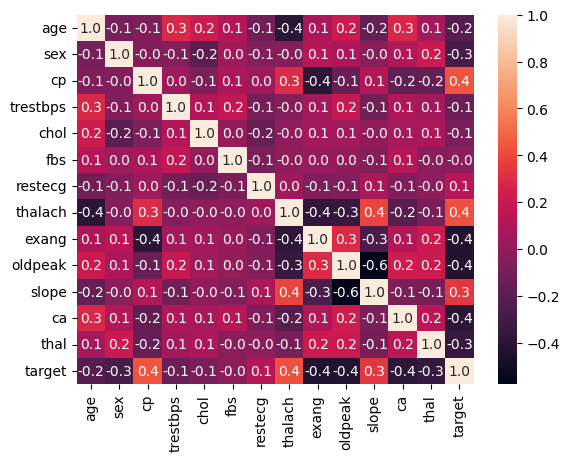

In [17]:
sns.heatmap(df.corr(), annot=True, fmt=".1f")

The is no 'very high' correalation between the features and the target. There is a reasonably high positive correlation for `cp`, `thalach`, and `slope` and negative correaltion for `sex`, `exang`, `oldpeak`, `ca`, and `thal`.

<Axes: xlabel='age', ylabel='Count'>

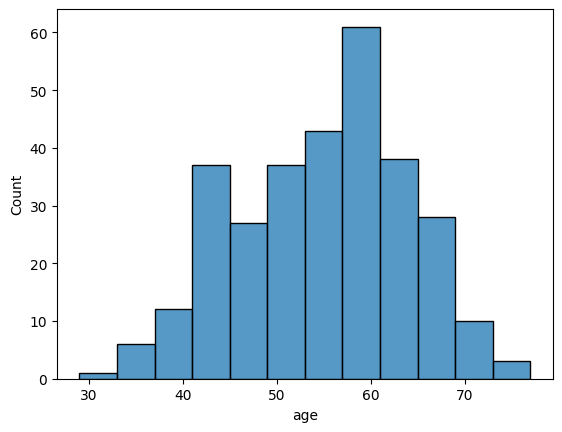

In [39]:
sns.histplot(df['age'])

Looks like 50-60 year olds dominate the dataset

<Axes: xlabel='trestbps', ylabel='Count'>

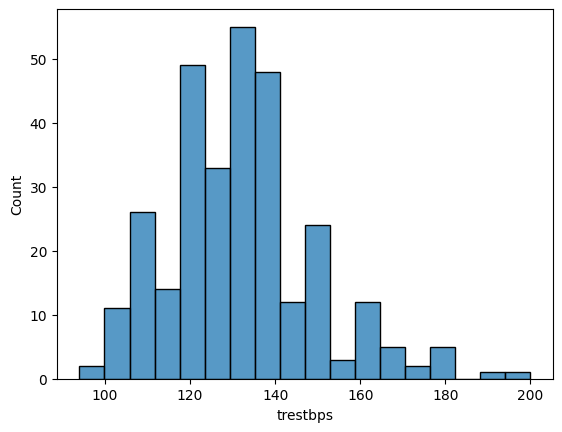

In [34]:
sns.histplot(df['trestbps'])

There are quite a few outliers around the tail (>160)

<Axes: xlabel='chol', ylabel='Count'>

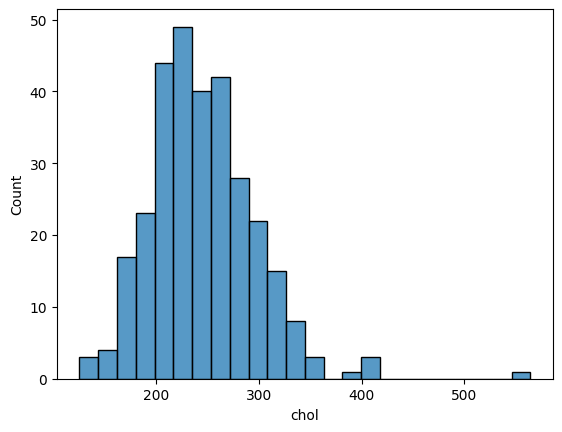

In [18]:
sns.histplot(df['chol'])

Again, few outlier are in here.

<Axes: xlabel='thalach', ylabel='Count'>

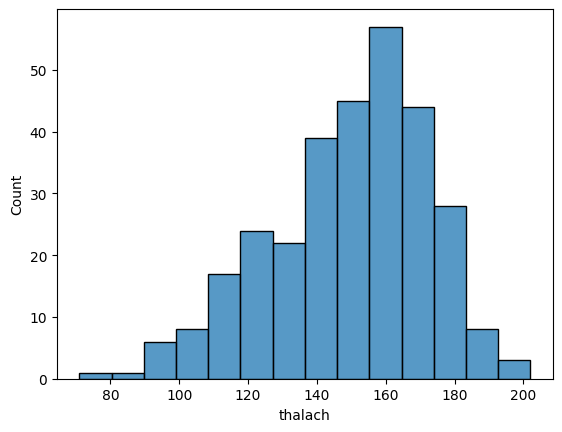

In [27]:
sns.histplot(df['thalach'])

<Axes: xlabel='oldpeak', ylabel='Count'>

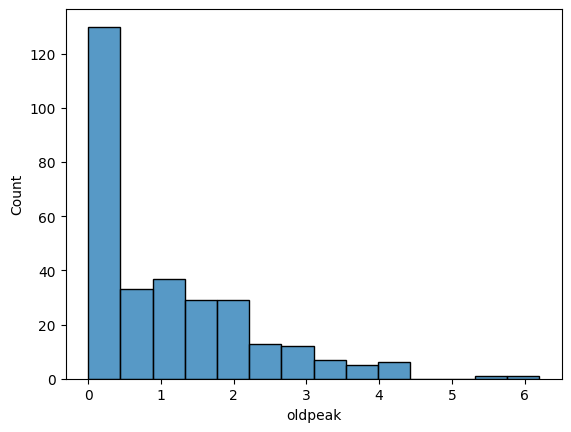

In [29]:
sns.histplot(df['oldpeak'])

Very high skew towards 0-2 range

In [ ]:
df.drop('target', axis=1)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


## Task 03 - Preprocessing Pipeline

This dataset has mostly numerical features + a few categorical-like ones.

### Your job:
Implement `preprocess(df)` inside `src/preprocess.py` that:
- Splits into features X and target y
- Handles categorical encoding (if any; depends on version of dataset)
- Scales numerical features using `StandardScaler`
- Does NO imputation (clean dataset)
- Returns X, y ready for modeling

### Hint:
Even if everything is numeric, still use a `ColumnTransformer` — good practice.

Deliverable: modular preprocess function + test cell in notebook.